# 4.1 — Deterioration decomposition

**Goal**: explain the 2024 → 2025 rise in default (9.5% → 12.5%) by separating three mechanisms, each on its own over-time curve: **mix shift** (who applies), **policy effect** (who gets approved), and **within-segment deterioration** (how approved profiles perform).

**Input**: `data/processed/applications_segmented.parquet` (all 220,618 applications).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from matplotlib.ticker import PercentFormatter

from credit_policy import palette, save_fig

palette.apply_style()
PROJECT_DIR = Path.cwd().parent
FIG_DIR = PROJECT_DIR / "reports" / "figures"

app = pd.read_parquet(PROJECT_DIR / "data" / "processed" / "applications_segmented.parquet")
app["approved"] = app["STATUS"].isin(["Aprovado", "Contratado"])
lab = app[app["OVER30M2"].notna()].copy()

SEGS = list(app["segmento"].cat.categories)
C_SEG = dict(zip(SEGS, ["#1c5cab", "#2a78d6", "#86b6ef", "#e34948", "#eb6834", "0.5"]))
SAFRAS = sorted(app["SAFRA"].unique())
X = range(len(SAFRAS))


def spread(vals, gap):
    """Nudge overlapping right-edge labels apart (keeps order)."""
    out, prev = {}, None
    for k, v in vals.sort_values().items():
        v = v if prev is None else max(v, prev + gap)
        out[k], prev = v, v
    return pd.Series(out)


def seg_lines(ax, wide, gap):
    """One line per segment over SAFRA, direct-labeled at the right edge."""
    for s in wide.columns:
        ls = "--" if s == "(missing)" else ":" if s == "total" else "-"
        ax.plot(X, wide[s], color=C_SEG.get(s, palette.INK), lw=1.4 if s == "total" else 2, ls=ls)
    ypos = spread(wide.iloc[-1].dropna(), gap)
    for s in ypos.index:
        ax.text(len(SAFRAS) - 0.6, ypos[s], s, color=C_SEG.get(s, palette.INK),
                fontsize=8.5, va="center")
    ax.set_xticks(X, [str(s) for s in SAFRAS], rotation=45, fontsize=8)
    ax.set_xlim(-0.5, len(SAFRAS) + 3.6)
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    sns.despine(ax=ax)


print(f"applications: {len(app):,} | labeled: {len(lab):,} @ {lab['OVER30M2'].mean():.2%}")

applications: 220,618 | labeled: 24,148 @ 10.30%


## 0. Maturity guard

`OVER30M2` is a fixed 2-month window — check it closed for every safra before reading any trend.

In [2]:
mat = (app[app["STATUS"] == "Contratado"].groupby("SAFRA")["OVER30M2"]
       .agg(contracted="size", labeled=lambda s: s.notna().mean(), default_rate="mean"))
mat.style.format({"labeled": "{:.0%}", "default_rate": "{:.2%}"})

,contracted,labeled,default_rate
SAFRA,,,
202406,1891,100%,10.10%
202407,1925,100%,8.94%
202408,1987,100%,10.27%
202409,1993,100%,9.73%
202410,2077,100%,9.53%
202411,2367,100%,9.42%
202412,1417,100%,8.26%
202501,1778,100%,10.18%
202502,1749,100%,10.35%


**Key takeaway**: all 13 safras are 100% labeled — the performance window is closed everywhere, so no safra needs to be discounted; 202506's 12.5% is real, not immaturity.

## 1. Mix shift — who applies

Segment share of *all* applications per safra: did riskier profiles start arriving?

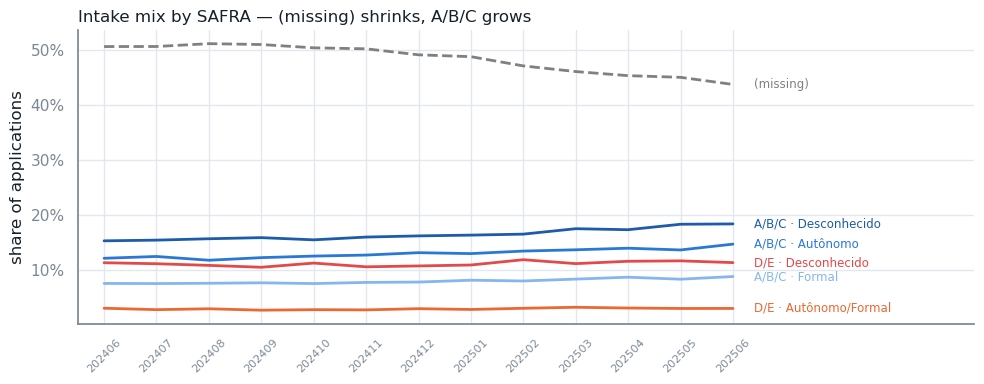

In [3]:
mix = app.pivot_table(index="SAFRA", columns="segmento", aggfunc="size", observed=False)
mix_sh = mix.div(mix.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(10, 4))
seg_lines(ax, mix_sh, gap=0.014)
ax.set_ylabel("share of applications")
ax.set_title("Intake mix by SAFRA — (missing) shrinks, A/B/C grows", loc="left")
plt.tight_layout()
plt.show()

**Key takeaway**: the intake mix moved the *safe* way — `(missing)` fell from 50.7% to 43.8% while every A/B/C cell grew — so the deterioration was **not imported** through who applies.

## 2. Policy effect — who gets approved

Approval rate and approved volume per segment: where did the ~54% → ~40% tightening land?

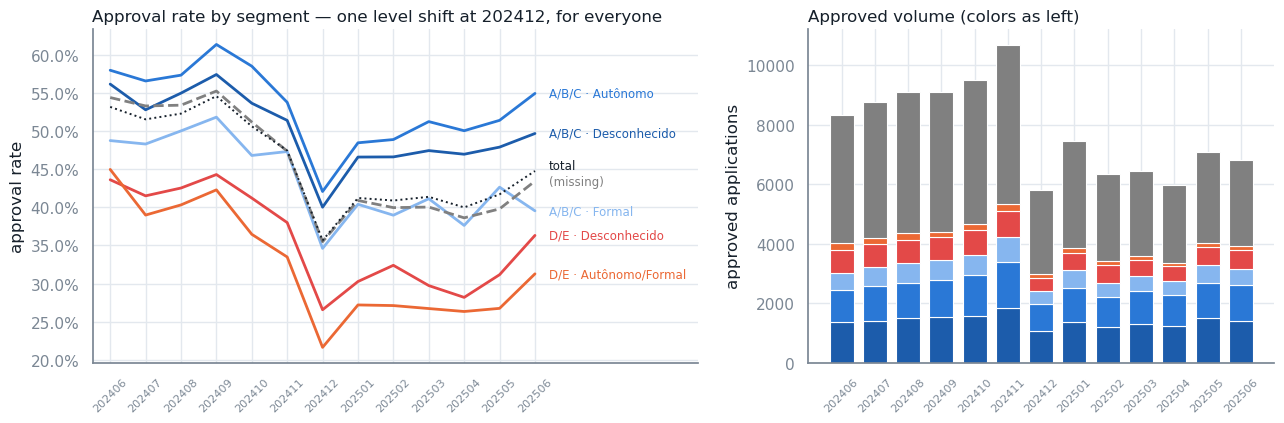

In [4]:
ar = app.pivot_table(index="SAFRA", columns="segmento", values="approved",
                    aggfunc="mean", observed=False)
ar["total"] = app.groupby("SAFRA")["approved"].mean()
vol = app[app["approved"]].pivot_table(index="SAFRA", columns="segmento",
                                       aggfunc="size", observed=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.4), width_ratios=[1.3, 1])
seg_lines(ax1, ar, gap=0.02)
ax1.set_ylabel("approval rate")
ax1.set_title("Approval rate by segment — one level shift at 202412, for everyone", loc="left")

bottom = pd.Series(0, index=vol.index)
for s in SEGS:
    ax2.bar(X, vol[s], bottom=bottom, color=C_SEG[s], width=0.72,
            edgecolor="white", linewidth=0.8)
    bottom = bottom + vol[s]
ax2.set_xticks(X, [str(s) for s in SAFRAS], rotation=45, fontsize=8)
ax2.set_ylabel("approved applications")
ax2.set_title("Approved volume (colors as left)", loc="left")
sns.despine(ax=ax2)
plt.tight_layout()
plt.show()

**Key takeaway**: 202412 is a single level shift (~−12pp) applied to *every* segment — volume tightening, not risk re-ordering: D/E fell most but the safest cells were cut too, and `A/B/C · Formal` stays approved **below** `A/B/C · Autônomo` in all 13 safras — the misordering found in 3.0 is chronic, not episodic.

## 3. Within-segment deterioration — how approved profiles perform

Default per segment per safra on the contracted book (thin cells n < 30 masked).

thin-cell guard: 0 of 78 cells masked (min n = 30)


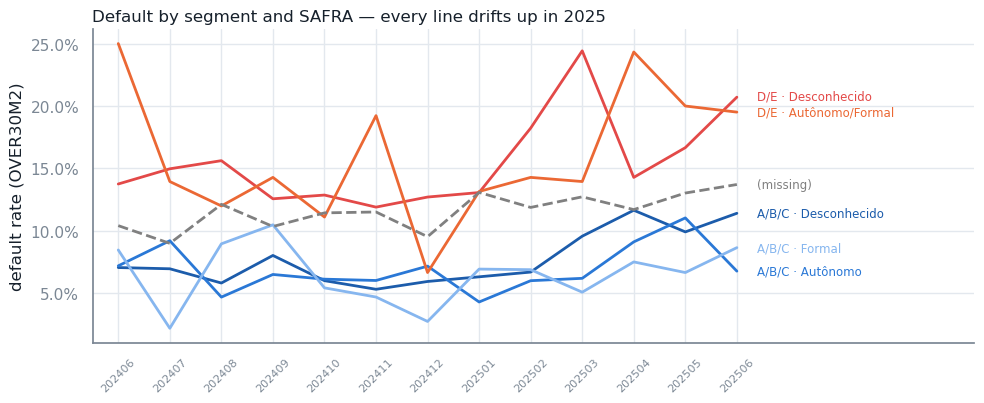

segmento,A/B/C · Desconhecido,A/B/C · Autônomo,A/B/C · Formal,D/E · Desconhecido,D/E · Autônomo/Formal,(missing)
year,,,,,,
2024,6.4%,6.6%,6.2%,13.5%,15.3%,10.7%
2025,9.3%,7.4%,6.9%,18.0%,17.5%,12.7%


In [5]:
dr = lab.pivot_table(index="SAFRA", columns="segmento", values="OVER30M2",
                    aggfunc="mean", observed=False)
n = lab.pivot_table(index="SAFRA", columns="segmento", aggfunc="size", observed=False)
dr = dr.where(n >= 30)
print(f"thin-cell guard: {int((n < 30).sum().sum())} of {n.size} cells masked (min n = {int(n.min().min())})")

fig, ax = plt.subplots(figsize=(10, 4.2))
seg_lines(ax, dr, gap=0.013)
ax.set_ylabel("default rate (OVER30M2)")
ax.set_title("Default by segment and SAFRA — every line drifts up in 2025", loc="left")
plt.tight_layout()
plt.show()

yr = (lab.assign(year=lab["SAFRA"] // 100)
      .pivot_table(index="year", columns="segmento", values="OVER30M2",
                   aggfunc="mean", observed=False))
yr.style.format("{:.1%}")

**Key takeaway**: every segment performs worse in 2025 (`A/B/C · Desconhecido` 6.4% → 9.3%, `D/E · Desconhecido` 13.5% → 18.0%, `(missing)` 10.7% → 12.7%) — the deterioration is **broad-based inside the cells**, not concentrated in one profile.

## 4. Shift-share decomposition

Hold segment default at pooled-2024 rates, let the book mix evolve: the counterfactual isolates the mix effect; the rest is within-segment performance.

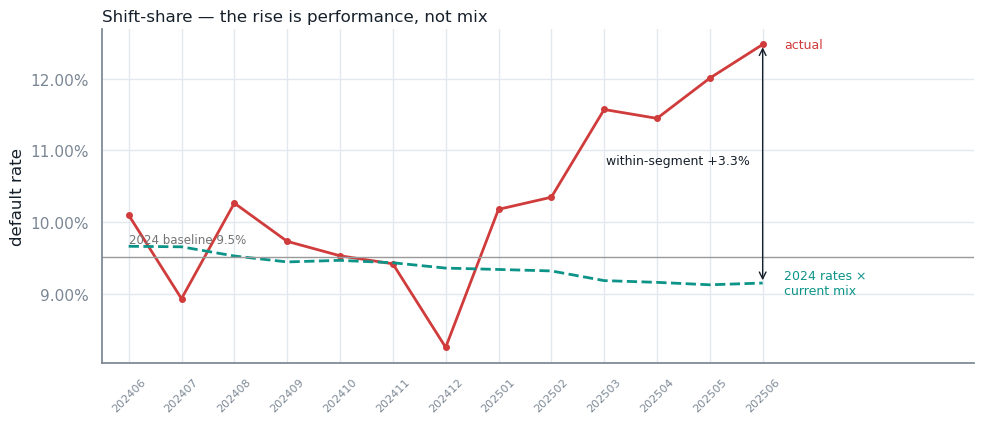

202506 vs 2024 baseline: total +2.97% = mix -0.36% + within-segment +3.32%


In [6]:
base = lab[lab["SAFRA"] <= 202412]
base_dr = base.groupby("segmento", observed=False)["OVER30M2"].mean()
base_rate = base["OVER30M2"].mean()

book_sh = n.div(n.sum(axis=1), axis=0)
cf = (book_sh * base_dr).sum(axis=1)               # 2024 rates x current book mix
actual = lab.groupby("SAFRA")["OVER30M2"].mean()
mix_eff, within_eff = cf - base_rate, actual - cf
assert ((mix_eff + within_eff) - (actual - base_rate)).abs().max() < 1e-12  # closes exactly

fig, ax = plt.subplots(figsize=(10, 4.4))
ax.plot(X, actual, color=palette.RISK_HIGH, lw=2, marker="o", ms=4)
ax.plot(X, cf, color=palette.RISK_LOW, lw=2, ls="--")
ax.axhline(base_rate, color="0.6", lw=1)
ax.text(len(SAFRAS) - 0.6, actual.iloc[-1], "actual", color=palette.RISK_HIGH,
        fontsize=9, va="center")
ax.text(len(SAFRAS) - 0.6, cf.iloc[-1], "2024 rates ×\ncurrent mix", color=palette.RISK_LOW,
        fontsize=9, va="center")
ax.text(0, base_rate + 0.002, f"2024 baseline {base_rate:.1%}", color="0.45", fontsize=8.5)
x_last = len(SAFRAS) - 1
ax.annotate("", (x_last, actual.iloc[-1]), (x_last, cf.iloc[-1]),
            arrowprops=dict(arrowstyle="<->", color=palette.INK))
ax.text(x_last - 0.25, (actual.iloc[-1] + cf.iloc[-1]) / 2,
        f"within-segment {within_eff.iloc[-1]:+.1%}", ha="right", fontsize=9, color=palette.INK)
ax.set_xticks(X, [str(s) for s in SAFRAS], rotation=45, fontsize=8)
ax.set_xlim(-0.5, len(SAFRAS) + 3.0)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylabel("default rate")
ax.set_title("Shift-share — the rise is performance, not mix", loc="left")
sns.despine()
plt.tight_layout()
save_fig(fig, "fig_deterioration_decomposition.png", FIG_DIR)
plt.show()

print(f"202506 vs 2024 baseline: total {actual.iloc[-1] - base_rate:+.2%} "
      f"= mix {mix_eff.iloc[-1]:+.2%} + within-segment {within_eff.iloc[-1]:+.2%}")

**Key takeaway**: of the **+3.0pp** rise at 202506 (9.5% → 12.5%), book mix contributes **−0.4pp** (the book actually got safer) and within-segment performance **+3.3pp** — tightening approvals improved the mix, but no approval cutoff fixes worse performance inside every cell; that points to macro/vintage causes and to pricing/limit levers, not more volume cuts.

## 5. Take-up check

`Contratado / (Aprovado + Contratado)` — did the applicants who accept change as the bar tightened?

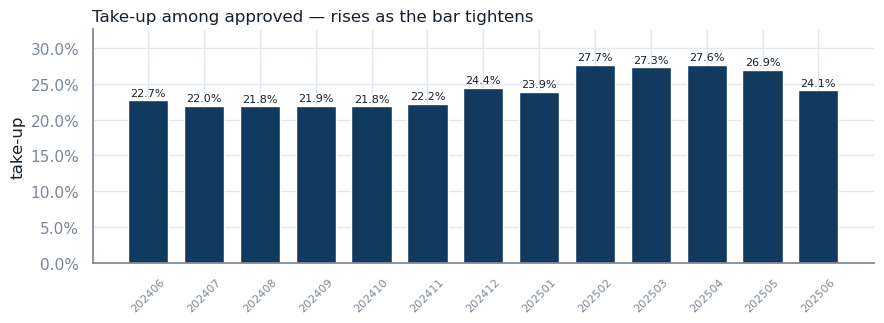

In [7]:
tu = (app[app["approved"]].groupby("SAFRA")["STATUS"]
      .apply(lambda s: (s == "Contratado").mean()))

fig, ax = plt.subplots(figsize=(9, 3.4))
bars = ax.bar(X, tu, color=palette.BRAND, width=0.72)
ax.bar_label(bars, labels=[f"{v:.1%}" for v in tu], fontsize=8, padding=2, color=palette.INK)
ax.set_xticks(X, [str(s) for s in SAFRAS], rotation=45, fontsize=8)
ax.set_ylim(0, tu.max() * 1.18)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylabel("take-up")
ax.set_title("Take-up among approved — rises as the bar tightens", loc="left")
sns.despine()
plt.tight_layout()
plt.show()

**Key takeaway**: take-up rose from ~22% (2024) to ~27% at the 2025 peak, right as approvals tightened — a mild **adverse-selection flag**: the approved applicants who *accept* are increasingly those with fewer outside options; worth watching, not yet actionable.